In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mutual_info_score

In [5]:
df = pd.read_csv('https://raw.githubusercontent.com/alexeygrigorev/datasets/master/course_lead_scoring.csv')
df.head()

,lead_source,industry,number_of_courses_viewed,annual_income,employment_status,location,interaction_count,lead_score,converted
0,paid_ads,NaN,1,79450.0,unemployed,south_america,4,0.94,1
1,social_media,retail,1,46992.0,employed,south_america,1,0.80,0
2,events,healthcare,5,78796.0,unemployed,australia,3,0.69,1
3,paid_ads,retail,2,83843.0,NaN,australia,1,0.87,0
4,referral,education,3,85012.0,self_employed,europe,3,0.62,1


In [6]:
print(df.shape)
df.info()

(1462, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1462 entries, 0 to 1461
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               1334 non-null   str    
 1   industry                  1328 non-null   str    
 2   number_of_courses_viewed  1462 non-null   int64  
 3   annual_income             1281 non-null   float64
 4   employment_status         1362 non-null   str    
 5   location                  1399 non-null   str    
 6   interaction_count         1462 non-null   int64  
 7   lead_score                1462 non-null   float64
 8   converted                 1462 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 102.9 KB


In [7]:
df.isnull().sum()

lead_source                 128
industry                    134
number_of_courses_viewed      0
annual_income               181
employment_status           100
location                     63
interaction_count             0
lead_score                    0
converted                     0
dtype: int64

In [8]:
df.describe()

,number_of_courses_viewed,annual_income,interaction_count,lead_score,converted
count,1462.000000,1281.000000,1462.000000,1462.000000,1462.000000
mean,2.031464,59886.273224,2.976744,0.506108,0.619015
std,1.449717,15070.140389,1.681564,0.288465,0.485795
min,0.000000,13929.000000,0.000000,0.000000,0.000000
25%,1.000000,49698.000000,2.000000,0.262500,0.000000
50%,2.000000,60148.000000,3.000000,0.510000,1.000000
75%,3.000000,69639.000000,4.000000,0.750000,1.000000
max,9.000000,109899.000000,11.000000,1.000000,1.000000


In [9]:
target = 'converted'
numerical = df.select_dtypes(include='number').columns.drop(target).tolist()
categorical = df.select_dtypes(exclude='number').columns.tolist()
print(numerical)
print(categorical)

['number_of_courses_viewed', 'annual_income', 'interaction_count', 'lead_score']
['lead_source', 'industry', 'employment_status', 'location']


In [10]:
display(df[categorical].nunique())
df[target].value_counts(normalize=True)

lead_source          5
industry             7
employment_status    4
location             7
dtype: int64

converted
1    0.619015
0    0.380985
Name: proportion, dtype: float64

In [11]:
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
df.isnull().sum().sum()

np.int64(0)

In [12]:
display(df['industry'].value_counts())
industry_mode = df['industry'].mode()[0]
industry_mode

industry
retail           203
finance          200
other            198
healthcare       187
education        187
technology       179
manufacturing    174
NA               134
Name: count, dtype: int64

'retail'

In [13]:
corr_matrix = df[numerical].corr()
corr_matrix.round(3)

,number_of_courses_viewed,annual_income,interaction_count,lead_score
number_of_courses_viewed,1.000,0.010,-0.024,-0.005
annual_income,0.010,1.000,0.027,0.016
interaction_count,-0.024,0.027,1.000,0.010
lead_score,-0.005,0.016,0.010,1.000


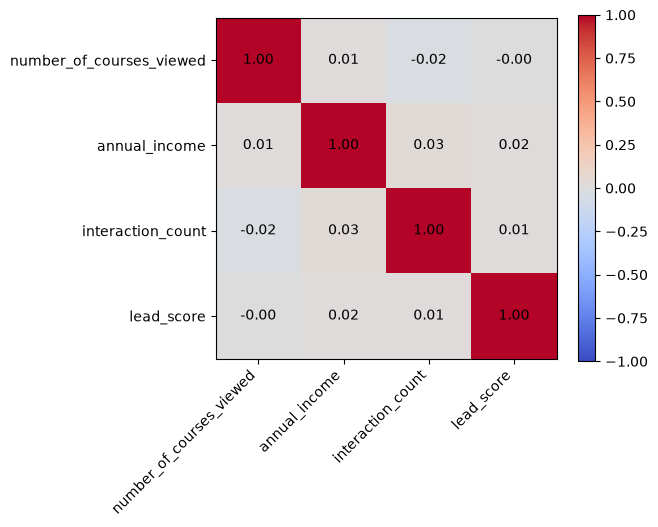

In [14]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr_matrix, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(numerical)), numerical, rotation=45, ha='right')
ax.set_yticks(range(len(numerical)), numerical)
for i in range(len(numerical)):
    for j in range(len(numerical)):
        ax.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}', ha='center', va='center')
fig.colorbar(im)
plt.show()

In [15]:
pairs = corr_matrix.abs().unstack()
pairs = pairs[pairs.index.get_level_values(0) < pairs.index.get_level_values(1)]
pairs.sort_values(ascending=False)

annual_income      interaction_count           0.027036
interaction_count  number_of_courses_viewed    0.023565
annual_income      lead_score                  0.015610
interaction_count  lead_score                  0.009888
annual_income      number_of_courses_viewed    0.009770
lead_score         number_of_courses_viewed    0.004879
dtype: float64

In [16]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

y_full_train = df_full_train[target].values
y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

df_full_train = df_full_train.drop(columns=target)
df_train = df_train.drop(columns=target)
df_val = df_val.drop(columns=target)
df_test = df_test.drop(columns=target)

y_train_series = pd.Series(y_train, index=df_train.index, name=target)

print(len(df_train), len(df_val), len(df_test))
print(y_train.mean(), y_val.mean(), y_test.mean())
print(target in df_train.columns)

876 293 293
0.6244292237442922 0.5563139931740614 0.6655290102389079
False


In [17]:
for c in categorical:
    display(y_train_series.groupby(df_train[c]).agg(['mean', 'count']).round(3))

,mean,count
lead_source,,
NA,0.730,89
events,0.617,154
organic_search,0.634,164
paid_ads,0.408,152
referral,0.820,150
social_media,0.587,167


,mean,count
industry,,
NA,0.551,78
education,0.802,106
finance,0.581,124
healthcare,0.624,117
manufacturing,0.642,109
other,0.624,117
retail,0.576,125
technology,0.590,100


,mean,count
employment_status,,
NA,0.561,66
employed,0.688,189
self_employed,0.650,220
student,0.679,221
unemployed,0.483,180


,mean,count
location,,
NA,0.684,38
africa,0.619,105
asia,0.614,114
australia,0.636,121
europe,0.685,130
middle_east,0.669,118
north_america,0.576,139
south_america,0.550,111


In [18]:
df_train[numerical].corrwith(y_train_series).sort_values(ascending=False)

number_of_courses_viewed    0.426480
interaction_count           0.369941
lead_score                  0.219223
annual_income               0.016605
dtype: float64

In [19]:
mi_scores = pd.Series({c: mutual_info_score(y_train, df_train[c]) for c in categorical})
display(mi_scores.sort_values(ascending=False))
mi_scores.round(2).sort_values(ascending=False)

lead_source          0.035396
employment_status    0.012938
industry             0.011575
location             0.004464
dtype: float64

lead_source          0.04
industry             0.01
employment_status    0.01
location             0.00
dtype: float64

In [20]:
features = categorical + numerical

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

print(X_train.shape, X_val.shape)
dv.get_feature_names_out()

(876, 31) (293, 31)


array(['annual_income', 'employment_status=NA',
       'employment_status=employed', 'employment_status=self_employed',
       'employment_status=student', 'employment_status=unemployed',
       'industry=NA', 'industry=education', 'industry=finance',
       'industry=healthcare', 'industry=manufacturing', 'industry=other',
       'industry=retail', 'industry=technology', 'interaction_count',
       'lead_score', 'lead_source=NA', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media', 'location=NA',
       'location=africa', 'location=asia', 'location=australia',
       'location=europe', 'location=middle_east',
       'location=north_america', 'location=south_america',
       'number_of_courses_viewed'], dtype=object)

In [21]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

train_accuracy = accuracy_score(y_train, model.predict(X_train))
val_accuracy = accuracy_score(y_val, model.predict(X_val))
baseline_accuracy = max(y_val.mean(), 1 - y_val.mean())

print('train:', round(train_accuracy, 4))
print('val:', round(val_accuracy, 4))
print('baseline:', round(baseline_accuracy, 4))
round(val_accuracy, 2)

train: 0.7386
val: 0.6997
baseline: 0.5563


0.7

In [22]:
pd.crosstab(y_val, model.predict(X_val), rownames=['actual'], colnames=['predicted'])

predicted,0,1
actual,,
0,50,80
1,8,155


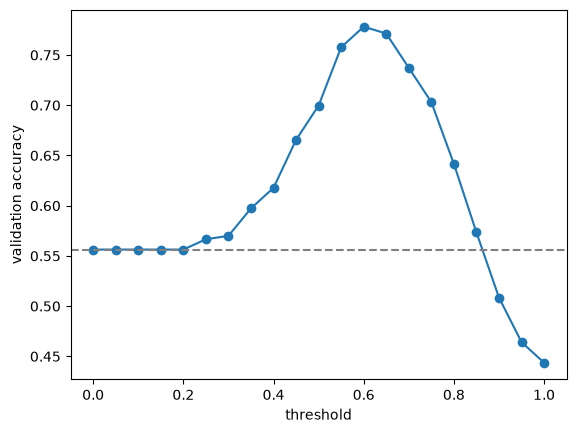

In [23]:
y_val_proba = model.predict_proba(X_val)[:, 1]
thresholds = np.linspace(0, 1, 21)
threshold_accuracies = [((y_val_proba >= t) == y_val).mean() for t in thresholds]

plt.plot(thresholds, threshold_accuracies, marker='o')
plt.axhline(baseline_accuracy, color='gray', linestyle='--')
plt.xlabel('threshold')
plt.ylabel('validation accuracy')
plt.show()

In [24]:
print('intercept:', round(model.intercept_[0], 4))
coefficients = pd.Series(model.coef_[0], index=dv.get_feature_names_out()).sort_values()
coefficients.round(4)

intercept: -0.0691


lead_source=paid_ads              -0.1153
employment_status=unemployed      -0.1025
location=north_america            -0.0334
industry=retail                   -0.0318
lead_source=social_media          -0.0299
location=south_america            -0.0253
industry=NA                       -0.0249
industry=finance                  -0.0201
industry=technology               -0.0161
employment_status=NA              -0.0147
industry=healthcare               -0.0134
lead_source=events                -0.0120
lead_source=organic_search        -0.0116
location=africa                   -0.0114
location=asia                     -0.0112
industry=other                    -0.0093
location=australia                -0.0056
industry=manufacturing            -0.0030
annual_income                     -0.0000
employment_status=self_employed    0.0027
location=NA                        0.0040
location=middle_east               0.0056
location=europe                    0.0083
employment_status=student         

In [25]:
def train(df, y, features=None, C=1.0):
    if features is None:
        features = categorical + numerical
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df[features].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
    model.fit(X, y)
    return dv, model


def predict_proba(df, dv, model, features=None):
    if features is None:
        features = categorical + numerical
    X = dv.transform(df[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]


def evaluate(df, y, dv, model, features=None):
    if features is None:
        features = categorical + numerical
    X = dv.transform(df[features].to_dict(orient='records'))
    return accuracy_score(y, model.predict(X))

In [26]:
all_features = categorical + numerical
reference_dv, reference_model = train(df_train, y_train)
reference_accuracy = evaluate(df_val, y_val, reference_dv, reference_model)
print(reference_accuracy == val_accuracy)

rows = []
for f in all_features:
    subset = [x for x in all_features if x != f]
    dv_f, model_f = train(df_train, y_train, features=subset)
    acc_f = evaluate(df_val, y_val, dv_f, model_f, features=subset)
    rows.append({'dropped': f, 'accuracy': acc_f, 'diff': reference_accuracy - acc_f})

elimination = pd.DataFrame(rows)
elimination['abs_diff'] = elimination['diff'].abs()
elimination.sort_values('diff').round(4)

True


,dropped,accuracy,diff,abs_diff
5,annual_income,0.8532,-0.1536,0.1536
3,location,0.7099,-0.0102,0.0102
7,lead_score,0.7065,-0.0068,0.0068
0,lead_source,0.7031,-0.0034,0.0034
1,industry,0.6997,0.0000,0.0000
2,employment_status,0.6962,0.0034,0.0034
4,number_of_courses_viewed,0.5563,0.1433,0.1433
6,interaction_count,0.5563,0.1433,0.1433


In [27]:
Cs = [0.000001, 0.00001, 0.0001, 0.001]
rows = []
for C in Cs:
    dv_c, model_c = train(df_train, y_train, C=C)
    rows.append({'C': C, 'val_accuracy': round(evaluate(df_val, y_val, dv_c, model_c), 3)})

c_results = pd.DataFrame(rows)
display(c_results)
c_results.sort_values(['val_accuracy', 'C'], ascending=[False, True]).iloc[0]

,C,val_accuracy
0,0.000001,0.556
1,0.000010,0.556
2,0.000100,0.556
3,0.001000,0.563


C               0.001
val_accuracy    0.563
Name: 3, dtype: float64

,C,val_accuracy
0,0.000001,0.556
1,0.000010,0.556
2,0.000100,0.556
3,0.001000,0.563
4,0.010000,0.700
5,0.100000,0.700
6,1.000000,0.700
7,10.000000,0.700
8,100.000000,0.700


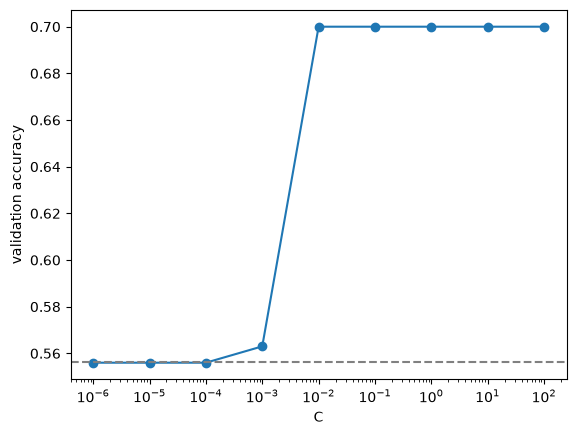

In [28]:
Cs_wide = [10.0 ** p for p in range(-6, 3)]
rows = []
for C in Cs_wide:
    dv_c, model_c = train(df_train, y_train, C=C)
    rows.append({'C': C, 'val_accuracy': round(evaluate(df_val, y_val, dv_c, model_c), 3)})

c_results_wide = pd.DataFrame(rows)
display(c_results_wide)

plt.plot(c_results_wide['C'], c_results_wide['val_accuracy'], marker='o')
plt.axhline(baseline_accuracy, color='gray', linestyle='--')
plt.xscale('log')
plt.xlabel('C')
plt.ylabel('validation accuracy')
plt.show()

In [29]:
scaler = StandardScaler()
df_train_scaled = df_train.copy()
df_val_scaled = df_val.copy()
df_train_scaled[numerical] = scaler.fit_transform(df_train[numerical])
df_val_scaled[numerical] = scaler.transform(df_val[numerical])

dv_scaled, model_scaled = train(df_train_scaled, y_train)
val_accuracy_scaled = evaluate(df_val_scaled, y_val, dv_scaled, model_scaled)
print('unscaled:', round(val_accuracy, 4))
print('scaled:', round(val_accuracy_scaled, 4))

unscaled: 0.6997
scaled: 0.8532


In [30]:
best_c = c_results_wide.sort_values(['val_accuracy', 'C'], ascending=[False, True]).iloc[0]['C']
print('best C:', best_c)

dv_final, model_final = train(df_full_train, y_full_train, C=best_c)
X_test = dv_final.transform(df_test[features].to_dict(orient='records'))
y_test_pred = model_final.predict(X_test)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_baseline = max(y_test.mean(), 1 - y_test.mean())
print('test:', round(test_accuracy, 4))
print('baseline:', round(test_baseline, 4))

best C: 0.01
test: 0.7338
baseline: 0.6655


In [31]:
pd.crosstab(y_test, y_test_pred, rownames=['actual'], colnames=['predicted'])

predicted,0,1
actual,,
0,31,67
1,11,184


In [32]:
customer = df_test.iloc[0][features].to_dict()
X_customer = dv_final.transform([customer])

print(customer)
print('P(convert):', round(model_final.predict_proba(X_customer)[0, 1], 3))
print('actual:', y_test[0])

{'lead_source': 'social_media', 'industry': 'manufacturing', 'employment_status': 'self_employed', 'location': 'middle_east', 'number_of_courses_viewed': 2, 'annual_income': 56070.0, 'interaction_count': 2, 'lead_score': 0.23}
P(convert): 0.598
actual: 1
